# Riemannian flow matching on EB differentiation in three genes

**Contents.** The swiss-roll pipeline, applied to real cells: embryoid-body (EB) differentiation (`eb_ot_v2`) seen through the genes MDK, RPL12 and VIM.
1. The data in three genes, restricted to cells that express all three, and a train/validation/test split stratified by time point.
2. The graph, biharmonic embedding and continuous Nyström extension, built **only on training cells** (a subsample over all five time points), for the five symmetric kernel profiles of the swiss roll. Exact RFM fields and Euler trajectories per profile.
3. Training CellFlow RFM from the $t=0$ cells (source) to the $t=1$ cells (target) of the training split; evaluation on the held-out validation and test cells.
4. Four-way comparison: Riemannian vs. Euclidean flow matching × biharmonic vs. Euclidean OT couplings.
5. Learned intermediate marginals against the held-out cells observed at $t=0.25, 0.5, 0.75$, and learned trajectories of held-out cells.

On the swiss roll, the domain is known analytically, so the notebook can project onto it, guard its boundary and compute exact geodesics. Here the domain is only known through cells. Its role is played by the **support of the fitted kernel** around the training cells: a state is *supported* if at least one training cell gives it a non-zero affinity, otherwise the Nyström embedding has no gradient there and RFM cannot move it. The only constraint known exactly is that log-expression is non-negative, so the RFM interpolation clips to $x\ge 0$ after every step, in the role of the roll projection. There is no ground-truth geodesic, so the reference-path and loss-mode sections of the swiss-roll notebook have no counterpart here. Instead, the observed intermediate time points provide real intermediate marginals.

The reusable code lives in the `riemannian_toys` package next to it (run the notebook from `docs/notebooks`):

| Module | Content |
| --- | --- |
| `riemannian_toys.cells` | gene view, stratified group split, graph construction set, the kernel-support domain `CellCloud`, metrics, 3-D plots |
| `riemannian_toys.kernels` | kernel-profile fits, Euler integration of the exact RFM field |
| `riemannian_toys.flows` | AnnData for one transport condition, OT matching, training, prediction, learned paths |
| `riemannian_toys.comparison` | training the four-way comparison |
| `riemannian_toys.plotting` | matrices and loss panels |

Library pieces it builds on: `cellflow.preprocessing.fit_kernel_nystroem` and `cellflow.ode_solver.RFMInterpolation`.

In [1]:
import os
import warnings

import anndata as ad
import jax
import jax.numpy as jnp
import numpy as np
import optax
import pandas as pd
import scanpy as sc
from IPython.display import display
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

from riemannian_toys import cells, comparison, flows, kernels, plotting

warnings.simplefilter("ignore", FutureWarning)

## The data in three genes

`eb_prepared.h5ad` holds 18,203 cells × 1,241 genes of an EB differentiation time course with five sampling times, `experimental_time` $\in\{0, 0.25, 0.5, 0.75, 1\}$. Note that `.X` holds **integer counts**, rescaled per cell (see `uns['provenance']`). We normalize every cell to 10,000 counts and take $\log(1+x)$ over all 1,241 genes, as in `data/eb_ot_v2.ipynb`, and then keep MDK, RPL12 and VIM. Normalization is per cell, so it does not mix the splits. Every cell becomes a point $x\in\mathbb R^3_{\ge 0}$.

**Why these genes.** MDK, RPL12 and VIM were chosen on the benchmark's training cells (`obs['split'] == 'train'`, so never on its validation cells) among the 81 genes detected in at least half of the cells. Over all triples of those genes, they combine the strongest time structure (41% of each cell's 15 nearest neighbours in the three z-scored genes come from its own time point, against 21% for random neighbours) with little redundancy (no pairwise correlation above 0.3), while 91% of the cells express all three. RPL12 falls with time, VIM rises, and MDK peaks in the middle. RPL12 is ribosomal and VIM a broad mesenchymal marker, so the time signal partly reflects global changes rather than specific lineages.

**We keep only cells that express all three genes.** These genes are well expressed: nearly every kept cell is its own point in $\mathbb R^3$, with no pile-up at the origin or on the coordinate axes, unlike sparse marker genes.

In [2]:
data_path = "/ictstr01/groups/ml01/workspace/markus.laengst/data/eb_ot_v2/eb_prepared.h5ad"
if not os.path.exists(data_path):  # the GPU nodes mount the same workspace under /lustre
    data_path = data_path.replace("/ictstr01/", "/lustre/", 1)
gene_symbols = ["MDK", "RPL12", "VIM"]

adata = ad.read_h5ad(data_path)
print(adata)
print("provenance:", adata.uns["provenance"])
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

genes = cells.find_genes(adata.var_names, gene_symbols)
X = cells.gene_view(adata, genes)
time = adata.obs["experimental_time"].to_numpy(dtype=np.float64)
time_levels = np.unique(time)
print("genes:", genes)

detected = (X > 0).sum(axis=1)
_, multiplicities, _ = cells.unique_points(X)
display(pd.DataFrame({
    "cells": pd.Series(time).value_counts().sort_index(),
    "all three detected": pd.Series(time[detected == 3]).value_counts().sort_index() / pd.Series(time).value_counts().sort_index(),
    **{f"{s} detected": pd.Series(time[X[:, j] > 0]).value_counts().sort_index() / pd.Series(time).value_counts().sort_index()
       for j, s in enumerate(gene_symbols)},
    **{f"mean {s}": pd.Series(X[:, j]).groupby(time).mean() for j, s in enumerate(gene_symbols)},
}).rename_axis("time").round(3))
print(f"{len(X)} cells on {len(multiplicities)} distinct points; largest multiplicity {multiplicities.max()}")

AnnData object with n_obs × n_vars = 18203 × 1241
    obs: 'experimental_time', 'day_index', 'sample_labels', 'total_counts', 'library_x_counts', 'exposure_counts', 'split', 'duplicate_group'
    uns: 'provenance'
    layers: 'X_counts', None (.X)
provenance: {'plan': 'flatvi_eb_ot_v2', 'rescale_total': 4134.0, 'source': 'eb_phate.h5ad', 'source_sha256': 'fa0718938ff5b824b235f454590d62c29512403cc08fbbfeb5cf0973b64684ff'}


genes: ['MDK (ENSG00000110492)', 'RPL12 (ENSG00000197958)', 'VIM (ENSG00000026025)']


,cells,all three detected,MDK detected,RPL12 detected,VIM detected,mean MDK,mean RPL12,mean VIM
time,,,,,,,,
0.00,2656,0.738,0.993,1.000,0.742,4.521,6.106,2.766
0.25,4374,0.902,1.000,1.000,0.902,5.360,5.991,4.230
0.50,3650,0.952,0.999,1.000,0.952,5.567,5.759,4.537
0.75,3873,0.959,0.996,1.000,0.963,5.246,5.559,4.657
1.00,3650,0.966,0.989,0.994,0.982,5.019,5.014,5.559


18203 cells on 18178 distinct points; largest multiplicity 2


In [3]:
# Keep only cells that express all three genes.
expressing = (X > 0).all(axis=1)
display(pd.DataFrame({
    "cells": pd.Series(time).value_counts().sort_index(),
    "kept": pd.Series(time[expressing]).value_counts().sort_index(),
}).assign(kept_fraction=lambda df: df["kept"] / df["cells"]).rename_axis("time").round(3))
adata = adata[expressing].copy()
X, time = X[expressing], time[expressing]
_, multiplicities, _ = cells.unique_points(X)
assert np.all(X > 0)
print(f"{len(X)} cells kept on {len(multiplicities)} distinct points; largest multiplicity {multiplicities.max()}")

,cells,kept,kept_fraction
time,,,
0.00,2656,1959,0.738
0.25,4374,3945,0.902
0.50,3650,3473,0.952
0.75,3873,3714,0.959
1.00,3650,3525,0.966


16616 cells kept on 16593 distinct points; largest multiplicity 2


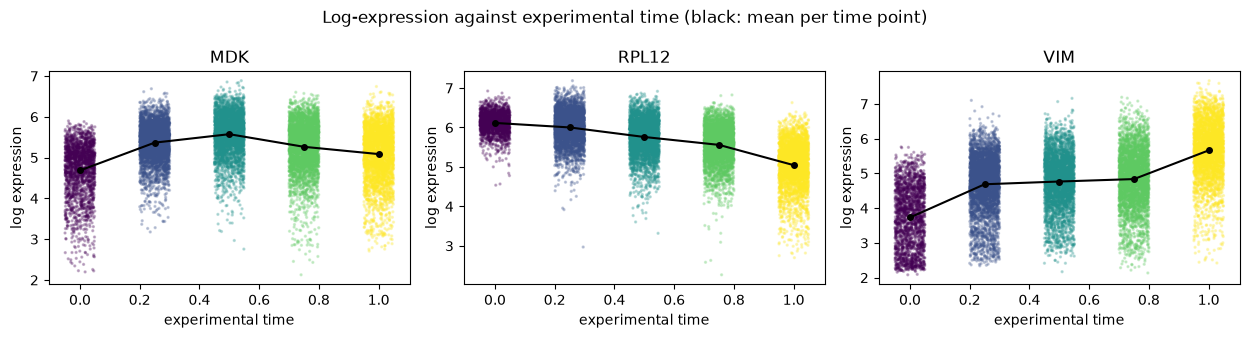

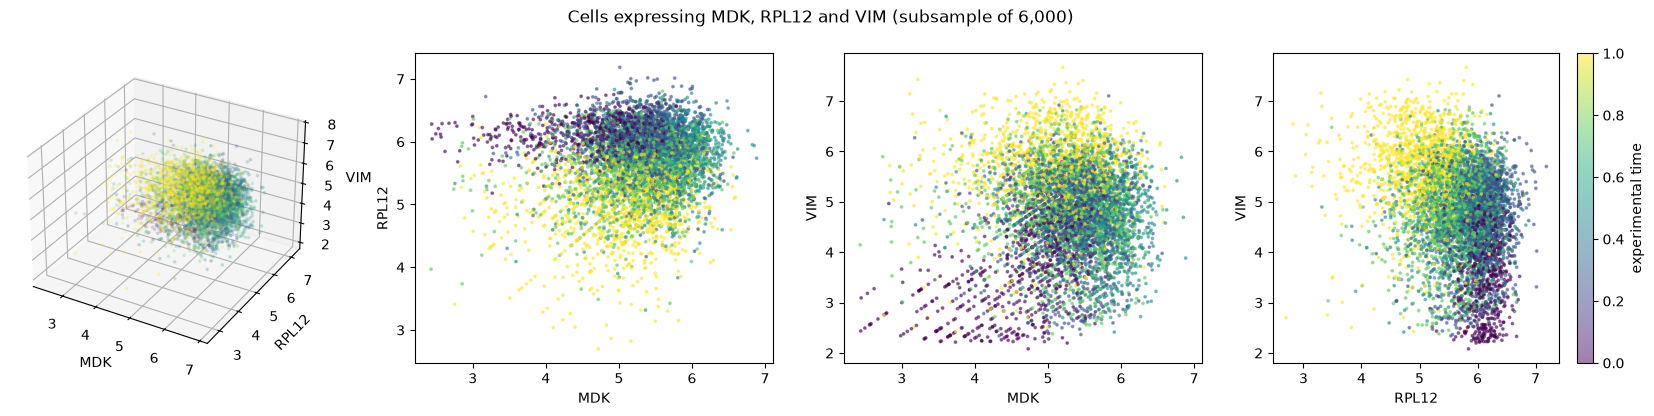

In [4]:
cells.plot_time_trends(X, time, genes, "Log-expression against experimental time (black: mean per time point)")
cells.plot_gene_view(X, time, genes, "Cells expressing MDK, RPL12 and VIM (subsample of 6,000)")

RPL12 falls and VIM rises steadily with time; MDK rises up to $t=0.5$ and then falls slightly. The clouds of neighbouring time points overlap strongly, but $t=0$ and $t=1$ are well separated. The filter removes mostly early cells (VIM is detected in only about three quarters of the $t=0$ cells), so the kept cells slightly over-represent later times.

## Train / validation / test split

The split is new, not the benchmark's `obs['split']` (which only has a training and a validation part). Within every time point, 70% of the cells go to training, 10% to validation and 20% to test. `duplicate_group` is respected: all cells of one group land in the same split (in this file every group has one cell, so this is a safeguard).

| Split | Used for |
| --- | --- |
| train | the source ($t=0$) and target ($t=1$) clouds of flow matching, and **the graph and its Nyström extension** (all five time points) |
| val | evaluation only: never seen by training or by the geometry |
| test | evaluation only: never seen by training or by the geometry |

The geometry uses the training cells of all time points, not only $t=0$ and $t=1$. The intermediate states then lie in the kernel support, so RFM paths can pass through them. Validation and test cells enter neither the graph nor training; the notebook asserts this below.

In [5]:
split_fractions = {"train": 0.7, "val": 0.1, "test": 0.2}
split_seed = 0
split = cells.stratified_group_split(time, adata.obs["duplicate_group"].astype(str).to_numpy(), split_fractions, split_seed)
adata.obs["rfm_split"] = pd.Categorical(split, categories=cells.SPLITS)
display(cells.split_table(split, time))


def cells_at(split_name, t):
    return X[(split == split_name) & np.isclose(time, t)]


source_time, target_time = 0.0, 1.0
for name in cells.SPLITS:
    print(f"{name}: source (t=0) {len(cells_at(name, source_time))} cells, target (t=1) {len(cells_at(name, target_time))} cells")

time,0.0,0.25,0.5,0.75,1.0,All
split,,,,,,
train,1371,2762,2431,2600,2468,11632
val,196,394,347,371,352,1660
test,392,789,695,743,705,3324
All,1959,3945,3473,3714,3525,16616


train: source (t=0) 1371 cells, target (t=1) 2468 cells
val: source (t=0) 196 cells, target (t=1) 352 cells
test: source (t=0) 392 cells, target (t=1) 705 cells


## The graph on the training cells

The graph uses a random subsample of `graph_max_cells` = 4,000 training cells, drawn over all five time points. The RFM loss evaluates the Nyström extension, whose cost grows with the number of graph points, at every interpolation step, so the subsample keeps an RFM run at a few minutes on a CPU. Validation and test cells never enter the graph. Identical points would have zero distance to their nearest neighbours, and their CkNN bandwidth $\rho_i$ would vanish, so the graph is built on the distinct points of the subsample (here nearly all of them).

The kernels are the swiss roll's symmetric variable-bandwidth profiles on a common CkNN support, $\rho_i=\|x_i-x_{i,k_\rho}\|$, $s_{ij}=\|x_i-x_j\|^2/(\delta^2\rho_i\rho_j)$, with edges where $s_{ij}<1$:

| Profile | Weight on a CkNN edge ($s<1$) |
| --- | --- |
| Fixed Gaussian | $\exp(-\|x-y\|^2/(2\sigma^2))$ |
| Variable Gaussian | $\exp(-s/2)$ |
| Compact polynomial | $(1-s)^4$ |
| Smooth bump | $\exp(1-1/(1-s))$ |
| Binary CkNN | $1$ |

The settings are the swiss roll's: $k_\rho=24$, $\delta=2$. (On sparse marker genes such as MT1X, JUN and GSTM3, the gaps between "detected" and "not detected" forced much larger supports, and RFM still failed there; continuously expressed genes avoid this.)

As on the swiss roll, $L=D-W$, 32 biharmonic modes, and $\Psi_k(x)=\phi_k(x)/(\lambda_k+10^{-8})$ for the continuous Nyström extension.

In [6]:
# The graph uses a subsample of the training split only.
graph_max_cells = 4000
graph_seed = 0
train_ids = np.flatnonzero(split == "train")
graph_ids = np.sort(np.random.default_rng(graph_seed).choice(train_ids, min(graph_max_cells, len(train_ids)), replace=False))
graph_mask = np.zeros(len(X), dtype=bool)
graph_mask[graph_ids] = True
graph_points = X[graph_mask]
graph_time = time[graph_mask]
construction_points, construction_counts, train_to_construction = cells.unique_points(graph_points)
construction_time = np.bincount(train_to_construction, weights=graph_time) / construction_counts  # mean time per point
print(f"{len(graph_points)} training cells → {len(construction_points)} distinct construction points; "
      f"largest multiplicity {construction_counts.max()}")

# No validation or test cell enters the graph: every construction point is the coordinate of a
# training cell, and the construction set is built from training rows only.
assert set(split[graph_mask]) == {"train"}
display(pd.crosstab(pd.Series(graph_time, name="time"), pd.Series(["graph cells"] * len(graph_time), name="")).T)

kernel_density_k = 24
kernel_delta = 2.0
kernel_n_modes = 32
kernel_laplacian_type = "unnormalized"
kernel_spectral_weight_type = "biharmonic"
cell_kernel_profiles = dict(kernels.KERNEL_PROFILES)

kernel_models, kernel_fitted, kernel_graphs, kernel_fit_df = kernels.fit_kernel_profiles(
    construction_points, cell_kernel_profiles, density_k=kernel_density_k, delta=kernel_delta,
    n_modes=kernel_n_modes, laplacian_type=kernel_laplacian_type, spectral_weight_type=kernel_spectral_weight_type,
)
display(kernel_fit_df)

4000 training cells → 4000 distinct construction points; largest multiplicity 1


time,0.00,0.25,0.50,0.75,1.00
,,,,,
graph cells,473,916,833,890,888


fixed Gaussian: fitted in 5.32s


variable Gaussian: fitted in 4.58s


compact polynomial: fitted in 4.48s


smooth bump: fitted in 4.37s


binary CkNN: fitted in 4.54s


,edges,components,min_degree,median_degree,lambda_2,max_eigen_residual,extension_relative_error,fit_seconds,retained_edge_fraction
kernel,,,,,,,,,
fixed Gaussian,338361,1,0.000072,36.381258,0.000072,6.342706e-14,6.573404e-09,5.322576,0.999997
variable Gaussian,338362,1,41.860231,130.080844,4.381452,2.892939e-13,9.706226e-08,4.580944,1.000000
compact polynomial,338362,1,4.367514,20.175477,0.270261,1.564825e-09,8.778747e-08,4.484749,1.000000
smooth bump,333668,1,14.220452,51.372367,1.017204,9.351885e-11,8.735552e-08,4.368621,0.986127
binary CkNN,338362,1,54.000000,173.000000,6.207041,4.800391e-08,8.654957e-08,4.537893,1.000000


,"|spearman(Psi_1, time)|","|spearman(Psi_2, time)|","|spearman(Psi_3, time)|"
fixed Gaussian,0.285,0.174,0.268
variable Gaussian,0.538,0.312,0.349
compact polynomial,0.540,0.304,0.358
smooth bump,0.539,0.306,0.356
binary CkNN,0.537,0.312,0.348


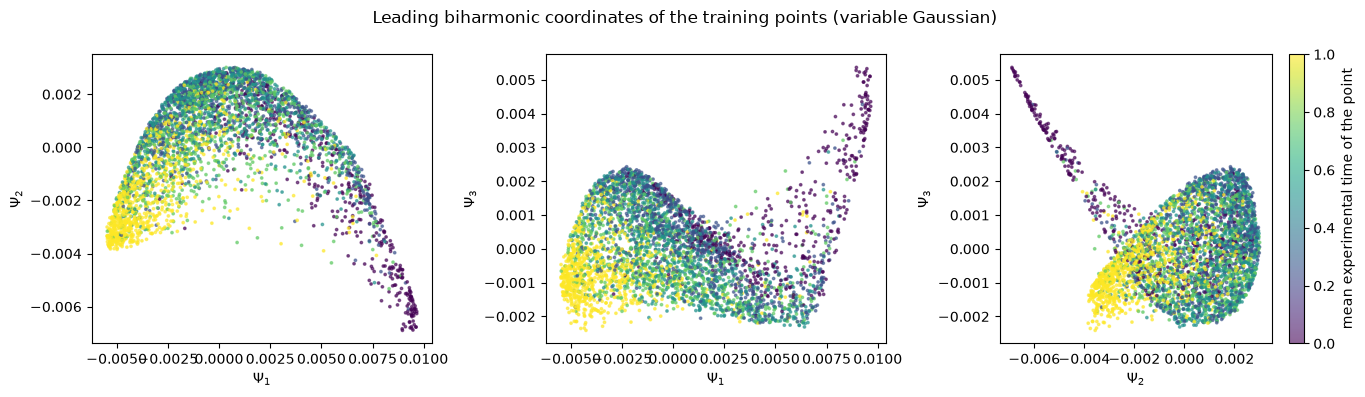

In [7]:
# Does the leading biharmonic coordinate order the cells in time? (Spearman correlation with the
# mean experimental time of each construction point, weighted by nothing: one value per point.)
kernel_time_df = pd.DataFrame({
    name: {f"|spearman(Psi_{k + 1}, time)|": abs(spearmanr(np.asarray(model.Psi)[:, k], construction_time)[0])
           for k in range(3)}
    for name, model in kernel_models.items()
}).T
display(kernel_time_df.round(3))
cells.plot_spectral_coordinates(np.asarray(kernel_models["variable Gaussian"].Psi), construction_time,
                                title="Leading biharmonic coordinates of the training points (variable Gaussian)")

### The domain: kernel support and non-negativity

`CellCloud` takes the role of `SwissRoll`. It knows the construction points and the fitted kernel, and provides

- `project`: clipping to $x\ge0$, used after every RFM interpolation step (log-expression is non-negative);
- `support_ratio(x)` $=\min_j\|x-x_j\|/(\delta\rho_j)$: below 1, the state lies in the CkNN support of at least one training point; `contains` thresholds it at 1;
- distances to the nearest construction point.

All support diagnostics below use the selected kernel's support; the CkNN support is the same for all five profiles.

### Exact RFM fields and trajectories per kernel profile

Before training, we integrate the exact conditional field $u_t(x\mid x_1)$ of every profile from 12 distinct training points at $t=0$ towards one target, the distinct $t=1$ training point closest to the mean of the $t=1$ training cells. As on the swiss roll, the Euler integration runs to $t=0.99$ in 800 steps, clips to $x\ge0$ after every step, and clips speeds above 30.

In [8]:
rfm_kernel_name = "variable Gaussian"
cloud = cells.CellCloud(construction_points, kernel_fitted[rfm_kernel_name])

for name in cells.SPLITS:
    for t in (source_time, target_time):
        print(f"{name}, t={t:g}: {cloud.contains(cells_at(name, t)).mean():.1%} of the cells lie in the kernel support")

target_candidates = construction_points[np.isclose(construction_time, target_time)]
kernel_target = target_candidates[np.argmin(np.linalg.norm(target_candidates - cells_at("train", target_time).mean(axis=0), axis=1))]
source_candidates = construction_points[np.isclose(construction_time, source_time)]
kernel_starts = source_candidates[np.random.default_rng(2026).choice(len(source_candidates), 12, replace=False)]
kernel_final_time, kernel_integration_steps = 0.99, 800
print("target:", np.round(kernel_target, 2))

kernel_paths, kernel_path_df = cells.exact_rfm_paths(
    kernel_models, cloud, kernel_starts, kernel_target, kernel_final_time, kernel_integration_steps,
    max_velocity_norm=30.0,
)
display(kernel_path_df)

train, t=0: 100.0% of the cells lie in the kernel support
train, t=1: 100.0% of the cells lie in the kernel support
val, t=0: 100.0% of the cells lie in the kernel support
val, t=1: 100.0% of the cells lie in the kernel support
test, t=0: 100.0% of the cells lie in the kernel support
test, t=1: 100.0% of the cells lie in the kernel support
target: [5.1  4.95 5.64]


,mean_final_error,max_final_error,mean_relative_error,mean_final_relative_biharmonic,mean_path_length,mean_straight_distance,max_support_ratio,clipped_step_fraction
kernel,,,,,,,,
fixed Gaussian,0.115225,0.783575,0.035059,0.008239,2.668575,2.183049,0.286675,0.0
variable Gaussian,0.000860,0.002625,0.000439,0.000186,2.922916,2.183049,0.308279,0.0
compact polynomial,0.022508,0.039850,0.010422,0.010312,2.542734,2.183049,0.308727,0.0
smooth bump,0.020661,0.036677,0.009608,0.011245,2.751579,2.183049,0.369059,0.0
binary CkNN,2.183049,3.827611,1.000000,1.000000,0.000000,2.183049,0.000000,0.0


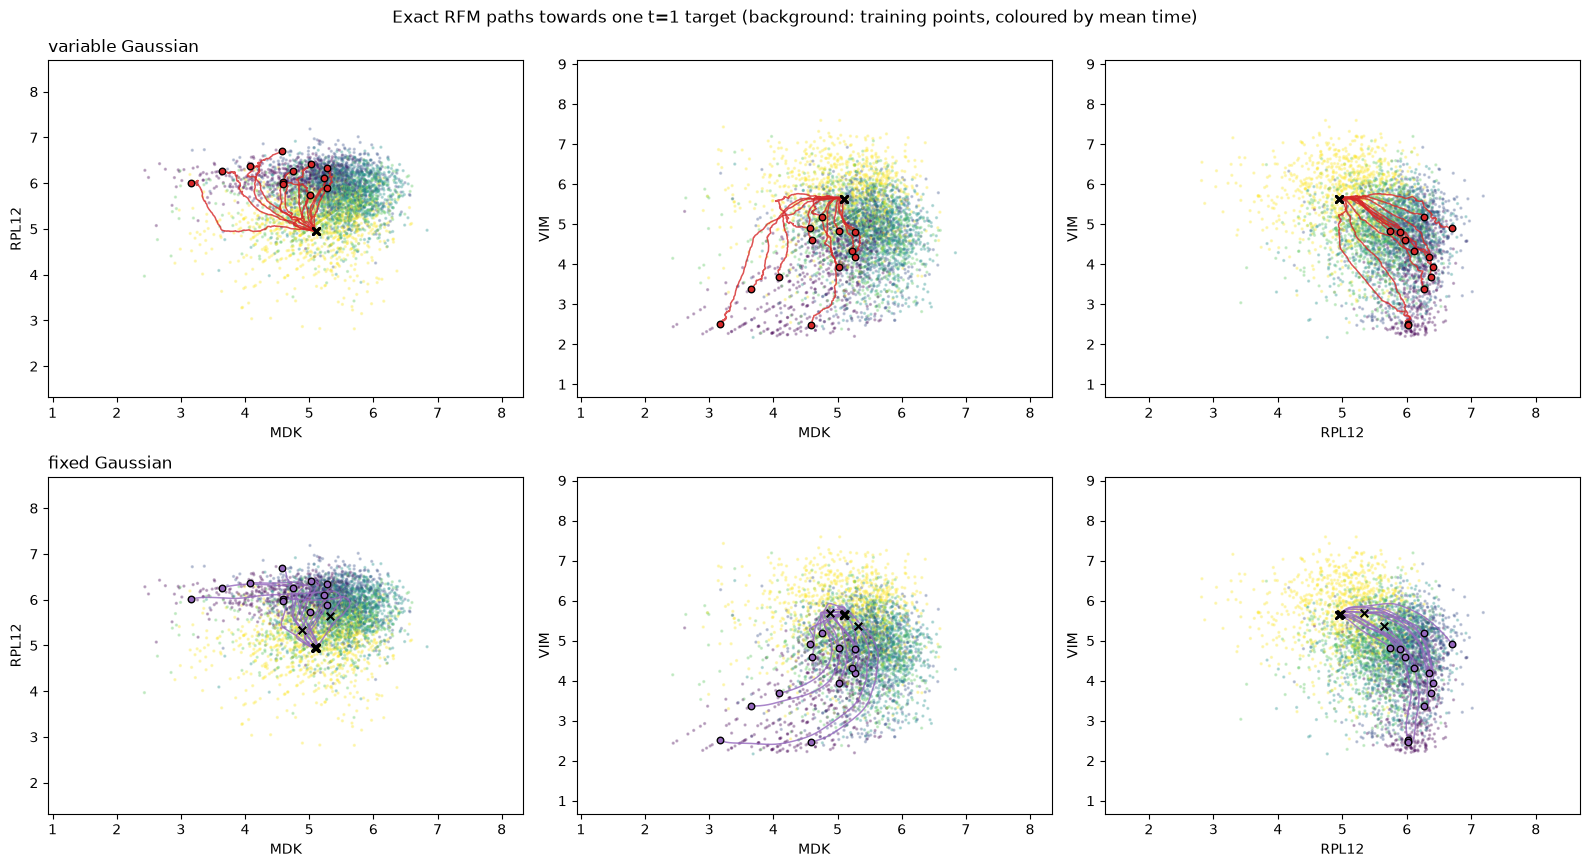

In [9]:
cells.plot_paths(
    construction_points, construction_time,
    {name: np.swapaxes(kernel_paths[name], 0, 1) for name in ["variable Gaussian", "fixed Gaussian"]},
    None, genes, "Exact RFM paths towards one t=1 target (background: training points, coloured by mean time)",
    colors={"variable Gaussian": "tab:red", "fixed Gaussian": "tab:purple"},
)

## Train CellFlow RFM from $t=0$ to $t=1$

The source/control distribution is the training split at $t=0$, the target the training split at $t=1$. As on the swiss roll, the selected Nyström model supplies the same biharmonic geometry to the OT matching and to the RFM interpolation:

$$c(x,y)=d_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2 .$$

`match_biharmonic` evaluates the Nyström embedding of each batch and calls `cellflow.utils.match_linear` with the unsquared embedding distance and relative $\varepsilon=0.05$. The workflow is the standard `CellFlow(..., solver="otrfm") → prepare_data → prepare_model → train`. The RFM interpolation clips to $x\ge 0$ after each of its 32 steps; prediction integrates the learned field without any clipping, and the evaluation reports negative expression.

The clouds are larger than the 250-point toy clouds (about 1,400 and 2,500 cells), so batches have 64 cells and training runs 1,000 iterations.

**Network.** Instead of the compact toy network (`flows.DEFAULT_ARCHITECTURE`), the velocity field takes the `"model"` section of `parameters.json`, a CellFlow configuration for drug combinations: FiLM conditioning, time and cell encoders of 2×512 units, a 2×1024 decoder, 1,024 time frequencies, a 128-dimensional condition embedding with attention-token pooling, and dropout in every part. Three entries are adapted:

- `layers_before_pool` is keyed by the perturbation covariate: `"condition"` there, `"transport"` here (any other key fails).
- Every layer spec is wrapped in a list. `prepare_model` builds layers only from a sequence of specs; a bare spec, as in the file, silently builds no layers.
- `probability_path={"constant_noise": 0.5}` is not used. The Riemannian solver ignores the probability path, and the Euclidean comparison models below keep the zero-noise straight path, so that no model is trained on noised paths. In these genes, a noise of 0.5 is as large as the per-gene standard deviation within one time point (0.3 to 0.8).

The file's `"training"` section (PCA input, Morgan fingerprints, 20,000 iterations of 512 cells, warm-up cosine schedule) belongs to the drug setting and is not used here.

In [10]:
rfm_nystroem = kernel_models[rfm_kernel_name]
rfm_ot_epsilon = 0.05
rfm_batch_size = 64
rfm_interpolation_steps = 32
rfm_num_iterations = 1000
rfm_seed = 2026
rfm_target_key, rfm_condition = "day_1", "t=1 cells"

# Velocity-field architecture from parameters.json["model"], adapted as described above.
rfm_architecture = {
    "condition_mode": "deterministic",
    "regularization": 0.0,
    "pooling": "attention_token",
    "pooling_kwargs": {},
    "layers_before_pool": {"transport": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.5}]},
    "layers_after_pool": [{"layer_type": "mlp", "dims": (512, 512), "dropout_rate": 0.1}],
    "condition_embedding_dim": 128,
    "cond_output_dropout": 0.3,
    "condition_encoder_kwargs": {},
    "pool_sample_covariates": True,
    "time_freqs": 1024,
    "time_encoder_dims": (512, 512),
    "time_encoder_dropout": 0.1,
    "hidden_dims": (512, 512),
    "hidden_dropout": 0.2,
    "conditioning": "film",
    "decoder_dims": (1024, 1024),
    "vf_act_fn": jax.nn.silu,
    "layer_norm_before_concatenation": False,
    "linear_projection_before_concatenation": False,
}

rfm_source = cells_at("train", source_time)
rfm_target = cells_at("train", target_time)

rfm_embed = jax.jit(jax.vmap(rfm_nystroem.extend_point))
match_biharmonic = flows.make_entropic_match_fn(rfm_ot_epsilon, embed=rfm_embed)
rfm_match_jit = jax.jit(match_biharmonic)

print(f"Geometry: {rfm_kernel_name} on {len(construction_points)} distinct training points, {rfm_nystroem.Psi.shape[1]} biharmonic modes")
print(f"Source: {rfm_source.shape}; target: {rfm_target.shape}")
print(f"Batch size: {rfm_batch_size}; interpolation steps: {rfm_interpolation_steps}; iterations: {rfm_num_iterations}")

Geometry: variable Gaussian on 4000 distinct training points, 32 biharmonic modes
Source: (1371, 3); target: (2468, 3)
Batch size: 64; interpolation steps: 32; iterations: 1000


,coupling diagnostics
coupling_mass,9.999999e-01
max_source_marginal_error,1.303852e-08
max_target_marginal_error,3.725290e-08
OT_mean_biharmonic_cost,9.556927e-03
independent_mean_biharmonic_cost,1.010315e-02


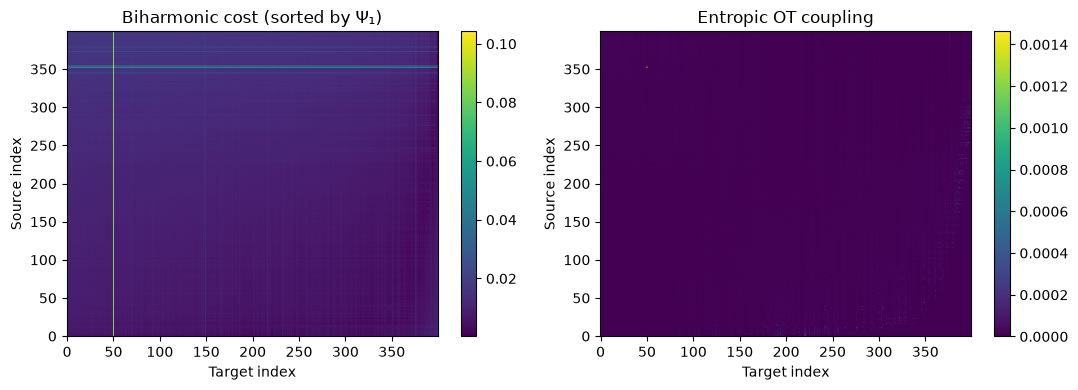

In [11]:
# Coupling diagnostics on a subsample of 400 source and 400 target cells; training recomputes
# the coupling on every batch.
diag_rng = np.random.default_rng(rfm_seed)
diag_source = rfm_source[diag_rng.choice(len(rfm_source), 400, replace=False)]
diag_target = rfm_target[diag_rng.choice(len(rfm_target), 400, replace=False)]
# Sort both by the leading biharmonic coordinate, so that the matrices show its ordering.
diag_source = diag_source[np.argsort(np.asarray(rfm_embed(jnp.asarray(diag_source)))[:, 0])]
diag_target = diag_target[np.argsort(np.asarray(rfm_embed(jnp.asarray(diag_target)))[:, 0])]

diag_cost = cdist(np.asarray(rfm_embed(jnp.asarray(diag_source))), np.asarray(rfm_embed(jnp.asarray(diag_target))))
diag_coupling = np.asarray(rfm_match_jit(diag_source, diag_target))
flows.check_coupling(diag_coupling, len(diag_source), len(diag_target))
flows.check_rectangular_batch(rfm_match_jit, diag_source, diag_target)

# The OT cost agrees with the distance used by RFM.
check_distances = rfm_nystroem.distance_grad_and_norm_batch(jnp.asarray(diag_source[:8]), jnp.asarray(diag_target[:8]))[0]
np.testing.assert_allclose(np.diag(diag_cost[:8, :8]), np.asarray(check_distances), rtol=1e-4, atol=1e-5)

display(flows.coupling_diagnostics(diag_coupling, diag_cost, "biharmonic"))
plotting.plot_matrices([(diag_cost, "Biharmonic cost (sorted by Ψ₁)"), (diag_coupling, "Entropic OT coupling")])

In [12]:
rfm_adata = flows.make_toy_adata(rfm_source, rfm_target, rfm_target_key)
rfm_cf = flows.prepare_toy_model(
    rfm_adata, "otrfm", rfm_target_key, **rfm_architecture,
    match_fn=match_biharmonic,
    nystroem=rfm_nystroem,
    optimizer=optax.adam(1e-3),
    solver_kwargs={
        "interpolation_steps": rfm_interpolation_steps,
        "projection_fn": cloud.project,
        "project_to_manifold": False,
        "max_velocity_norm": 30.0,
    },
    seed=rfm_seed,
)
print("Solver:", type(rfm_cf.solver).__name__)
print("Velocity-field parameters:", sum(p.size for p in jax.tree_util.tree_leaves(rfm_cf.solver.vf_state.params)))
print("Coordinate dimensions:", rfm_cf.train_data.cell_data.shape[1])
print("Control cells:", int(rfm_adata.obs[flows.SOURCE_KEY].sum()), "| target cells:", int(rfm_adata.obs[rfm_target_key].sum()))

[                                        ] | 0% Completed | 219.27 us

[########################################] | 100% Completed | 101.65 ms

[                                        ] | 0% Completed | 162.45 us

[########################################] | 100% Completed | 101.60 ms

[                                        ] | 0% Completed | 283.63 us

[########################################] | 100% Completed | 100.98 ms

Solver: OTRFlowMatching
Velocity-field parameters: 4273475
Coordinate dimensions: 3
Control cells: 1371 | target cells: 2468


In [13]:
rfm_losses, rfm_training_seconds = flows.train_timed(rfm_cf, rfm_num_iterations, rfm_batch_size)
print(f"Training finished in {rfm_training_seconds:.1f}s", flush=True)
print(f"Mean loss, first 25: {rfm_losses[:25].mean():.4f}; last 25: {rfm_losses[-25:].mean():.4f}")

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:09<2:30:08,  9.02s/it]

  1%|          | 10/1000 [00:09<10:55,  1.51it/s] 

  2%|▏         | 15/1000 [00:09<06:27,  2.54it/s]

  2%|▎         | 25/1000 [00:09<02:58,  5.45it/s]

  4%|▎         | 36/1000 [00:09<01:39,  9.69it/s]

... (99 outputs left out)

100%|█████████▉| 998/1000 [00:20<00:00, 84.16it/s, loss=13.6]

100%|██████████| 1000/1000 [00:20<00:00, 48.29it/s, loss=13.6]

Training finished in 20.7s


Mean loss, first 25: 16.1687; last 25: 12.3560


### Evaluation on held-out cells

Each split's $t=0$ cells are pushed through the learned field (the same inference weights, condition and Tsit5 solver as `CellFlow.predict`; on the training controls the result is checked against `predict`) and compared with the same split's $t=1$ cells. All metrics compare empirical distributions, without a pointwise pairing:

- squared energy distance and empirical $W_2$ (exact assignment on equal-size subsamples of at most 1,500 cells);
- the error of the mean;
- the fraction of predicted cells outside the kernel support, with negative expression, and the median distance to the nearest graph (training) point.

Two references bracket every number: the **unchanged source** (do nothing) and the **training $t=1$ cells**, an independent sample of the target distribution (the finite-sample floor).

[                                        ] | 0% Completed | 163.34 us

[########################################] | 100% Completed | 101.45 ms

[                                        ] | 0% Completed | 248.00 us

[########################################] | 100% Completed | 100.93 ms

energy_distance_squared  wasserstein_2  \
split cloud                                                                
val   unchanged source                             2.2707         2.2608   
      training t=1 cells (floor)                   0.0039         0.3773   
      RFM + biharmonic OT                          0.0619         0.6249   
test  unchanged source                             2.2831         2.3318   
      training t=1 cells (floor)                   0.0017         0.3087   
      RFM + biharmonic OT                          0.0664         0.6067   

                                  mean_error_to_target  unsupported_fraction  \
split cloud                                                                    
val   unchanged source                          2.2143                   0.0   
      training t=1 cells (floor)                0.0353                   0.0   
      RFM + biharmonic OT                       0.2685                   0.0   
test  unchanged source                          2.2526                   0.0   
      training t=1 cells (floor)                0.0245                   0.0   
      RFM + biharmonic OT                       0.2671                   0.0   

                                  negative_expression_fraction  \
split cloud                                                      
val   unchanged source                                     0.0   
      training t=1 cells (floor)                           0.0   
      RFM + biharmonic OT                                  0.0   
test  unchanged source                                     0.0   
      training t=1 cells (floor)                           0.0   
      RFM + biharmonic OT                                  0.0   

                                  median_distance_to_graph  diverged_fraction  
split cloud                                                                    
val   unchanged source                              0.0987                0.0  
      training t=1 cells (floor)                    0.0692                0.0  
      RFM + biharmonic OT                           0.1049                0.0  
test  unchanged source                              0.0911                0.0  
      training t=1 cells (floor)                    0.0692                0.0  
      RFM + biharmonic OT                           0.1065                0.0

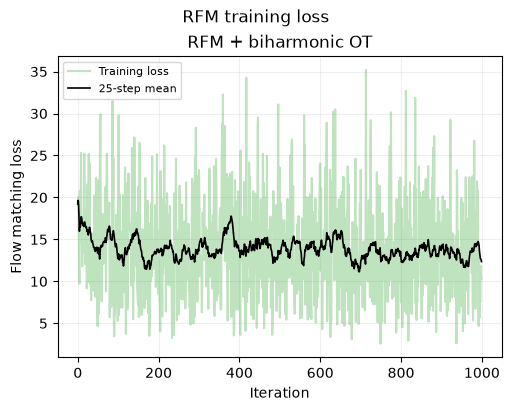

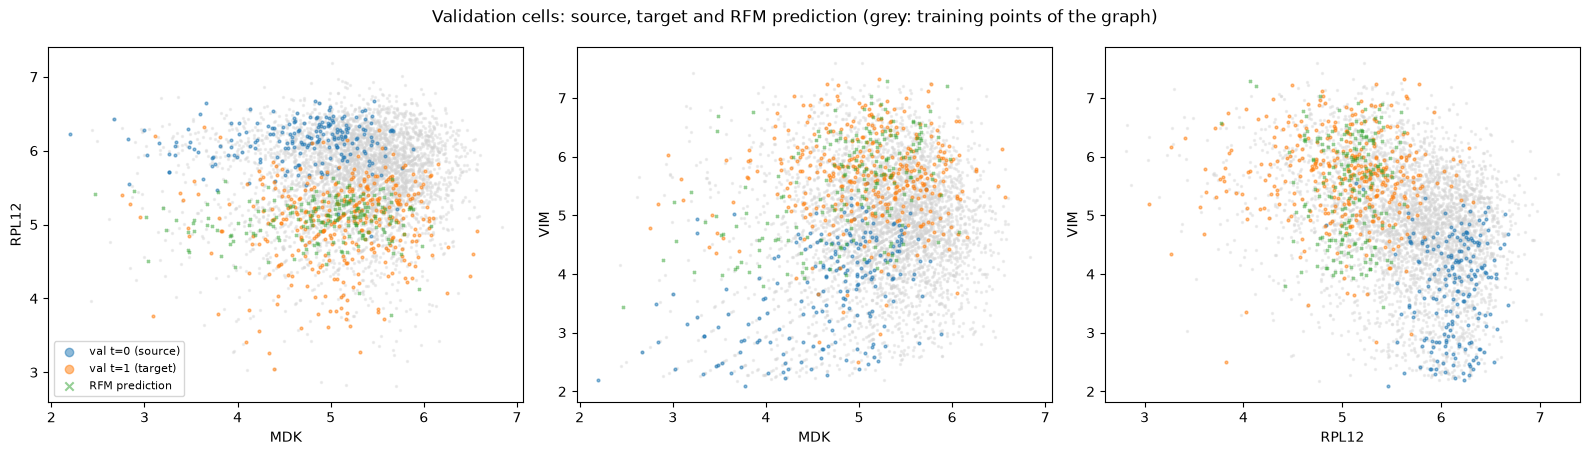

In [14]:
# Prediction from arbitrary start cells agrees with the public predict API on the training controls.
np.testing.assert_allclose(
    cells.predict_cells(rfm_cf, rfm_source), flows.predict_target(rfm_cf, rfm_adata, rfm_target_key, rfm_condition),
    rtol=1e-4, atol=1e-4,
)


def evaluate_split(models, split_name):
    source, target = cells_at(split_name, source_time), cells_at(split_name, target_time)
    clouds = {"unchanged source": source, "training t=1 cells (floor)": rfm_target}
    predictions = {name: cells.predict_cells(model, source) for name, model in models.items()}
    return cells.metric_table({**clouds, **predictions}, target, cloud), predictions


rfm_evaluation, rfm_predicted = {}, {}
for split_name in ("val", "test"):
    rfm_evaluation[split_name], rfm_predicted[split_name] = evaluate_split({"RFM + biharmonic OT": rfm_cf}, split_name)
display(pd.concat(rfm_evaluation, names=["split", "cloud"]).round(4))
plotting.plot_loss_panels({"RFM + biharmonic OT": rfm_losses}, {"RFM + biharmonic OT": "tab:green"}, "RFM training loss")
cells.plot_clouds(construction_points, {
    "val t=0 (source)": (cells_at("val", source_time), {"color": "tab:blue"}),
    "val t=1 (target)": (cells_at("val", target_time), {"color": "tab:orange"}),
    "RFM prediction": (rfm_predicted["val"]["RFM + biharmonic OT"], {"color": "tab:green", "marker": "x"}),
}, genes, "Validation cells: source, target and RFM prediction (grey: training points of the graph)")

Mean and standard deviation of each gene, for the source, the target and the prediction.

In [15]:
def moment_table(clouds):
    return pd.DataFrame({
        name: {**{f"mean {s}": np.mean(np.asarray(p)[:, j]) for j, s in enumerate(gene_symbols)},
               **{f"sd {s}": np.std(np.asarray(p)[:, j]) for j, s in enumerate(gene_symbols)}}
        for name, p in clouds.items()
    })


display(moment_table({
    "val t=0": cells_at("val", source_time), "val t=1": cells_at("val", target_time),
    "RFM prediction (val)": rfm_predicted["val"]["RFM + biharmonic OT"],
}).round(3))

,val t=0,val t=1,RFM prediction (val)
mean MDK,4.669,5.092,4.873
mean RPL12,6.117,5.019,5.063
mean VIM,3.782,5.658,5.510
sd MDK,0.680,0.641,0.681
sd RPL12,0.284,0.561,0.287
sd VIM,0.838,0.749,0.853


## Four-way comparison: Riemannian vs. Euclidean Flow Matching, biharmonic vs. Euclidean couplings

As on the swiss roll, the RFM model combines a **biharmonic OT coupling** (which source and target cells are paired) with **Riemannian interpolation** (how each pair is connected). The comparison trains all four combinations on the same clouds:

| | Biharmonic coupling $c_{\mathrm{BH}}(x,y)=\|\Psi(x)-\Psi(y)\|_2$ | Euclidean coupling $c_{\mathrm{E}}(x,y)=\|x-y\|_2$ |
| --- | --- | --- |
| **Riemannian FM** (`solver="otrfm"`) | `rfm_cf` (trained above) | `rfm_euclidean_cf` |
| **Euclidean FM** (`solver="otfm"`) | `fm_biharmonic_cf` | `fm_euclidean_cf` |

The Euclidean models use the zero-noise straight path $x_t=(1-t)x_0+tx_1$. Everything else is shared: network, optimizer, time sampler, EMA, batch size, iterations, initialization seed, and (for RFM) the interpolation settings, clipping included. Training losses regress different targets, so compare the evaluation metrics, not the losses.

In [16]:
cmp_seed = rfm_seed
match_euclidean = flows.make_entropic_match_fn(rfm_ot_epsilon)
cmp_match_euclidean_jit = jax.jit(match_euclidean)
flows.check_rectangular_batch(cmp_match_euclidean_jit, diag_source, diag_target)

diag_couplings = {"biharmonic": diag_coupling, "Euclidean": np.asarray(cmp_match_euclidean_jit(diag_source, diag_target))}
diag_costs = {"biharmonic": diag_cost, "Euclidean": cdist(diag_source, diag_target)}
display(pd.DataFrame({
    f"{coupling_name} coupling": {
        f"mean {cost_name} cost transported": float(np.sum(coupling * cost)) for cost_name, cost in diag_costs.items()
    } | {f"independent mean {cost_name} cost": float(cost.mean()) for cost_name, cost in diag_costs.items()}
    for coupling_name, coupling in diag_couplings.items()
}).round(4))


def build_comparison_model(solver, match_fn):
    return flows.build_matched_model(
        rfm_cf, rfm_adata, solver, match_fn, rfm_target_key, cmp_seed,
        nystroem=rfm_nystroem if solver == "otrfm" else None,
    )


cmp_models = {
    "RFM + biharmonic OT": rfm_cf,
    "RFM + Euclidean OT": build_comparison_model("otrfm", match_euclidean),
    "FM + biharmonic OT": build_comparison_model("otfm", match_biharmonic),
    "FM + Euclidean OT": build_comparison_model("otfm", match_euclidean),
}
cmp_colors = {
    "RFM + biharmonic OT": "tab:green",
    "RFM + Euclidean OT": "tab:cyan",
    "FM + biharmonic OT": "tab:purple",
    "FM + Euclidean OT": "tab:pink",
}
cmp_losses = {"RFM + biharmonic OT": rfm_losses}
cmp_training_seconds = {"RFM + biharmonic OT": rfm_training_seconds}
display(comparison.train_untrained(cmp_models, cmp_losses, cmp_training_seconds, rfm_num_iterations, rfm_batch_size))

,biharmonic coupling,Euclidean coupling
mean biharmonic cost transported,0.0096,0.0098
mean Euclidean cost transported,2.4562,2.3473
independent mean biharmonic cost,0.0101,0.0101
independent mean Euclidean cost,2.5809,2.5809


[                                        ] | 0% Completed | 224.65 us

[########################################] | 100% Completed | 101.62 ms

[                                        ] | 0% Completed | 113.26 us

[########################################] | 100% Completed | 100.85 ms

[                                        ] | 0% Completed | 116.64 us

... (254 outputs left out)

 99%|█████████▉| 993/1000 [00:08<00:00, 173.87it/s, loss=0.434]

100%|██████████| 1000/1000 [00:08<00:00, 113.86it/s, loss=0.434]

FM + Euclidean OT: 8.8s; mean loss first 25 1.11076, last 25 0.44353


,training_seconds,mean_loss_first_25,mean_loss_last_25
RFM + biharmonic OT,20.710280,16.168727,12.356026
RFM + Euclidean OT,16.947355,14.670063,11.358300
FM + biharmonic OT,10.989871,1.401243,0.718155
FM + Euclidean OT,8.784878,1.110761,0.443527


energy_distance_squared  wasserstein_2  \
split cloud                                                                
val   unchanged source                             2.2707         2.2608   
      training t=1 cells (floor)                   0.0039         0.3773   
      RFM + biharmonic OT                          0.0619         0.6249   
      RFM + Euclidean OT                           0.0900         0.6544   
      FM + biharmonic OT                           0.0476         0.5322   
      FM + Euclidean OT                            0.0196         0.4902   
test  unchanged source                             2.2831         2.3318   
      training t=1 cells (floor)                   0.0017         0.3087   
      RFM + biharmonic OT                          0.0664         0.6067   
      RFM + Euclidean OT                           0.1258         0.6592   
      FM + biharmonic OT                           0.0686         0.4976   
      FM + Euclidean OT                            0.0347         0.4385   

                                  mean_error_to_target  unsupported_fraction  \
split cloud                                                                    
val   unchanged source                          2.2143                   0.0   
      training t=1 cells (floor)                0.0353                   0.0   
      RFM + biharmonic OT                       0.2685                   0.0   
      RFM + Euclidean OT                        0.2730                   0.0   
      FM + biharmonic OT                        0.1942                   0.0   
      FM + Euclidean OT                         0.1341                   0.0   
test  unchanged source                          2.2526                   0.0   
      training t=1 cells (floor)                0.0245                   0.0   
      RFM + biharmonic OT                       0.2671                   0.0   
      RFM + Euclidean OT                        0.3625                   0.0   
      FM + biharmonic OT                        0.2691                   0.0   
      FM + Euclidean OT                         0.2101                   0.0   

                                  negative_expression_fraction  \
split cloud                                                      
val   unchanged source                                     0.0   
      training t=1 cells (floor)                           0.0   
      RFM + biharmonic OT                                  0.0   
      RFM + Euclidean OT                                   0.0   
      FM + biharmonic OT                                   0.0   
      FM + Euclidean OT                                    0.0   
test  unchanged source                                     0.0   
      training t=1 cells (floor)                           0.0   
      RFM + biharmonic OT                                  0.0   
      RFM + Euclidean OT                                   0.0   
      FM + biharmonic OT                                   0.0   
      FM + Euclidean OT                                    0.0   

                                  median_distance_to_graph  diverged_fraction  
split cloud                                                                    
val   unchanged source                              0.0987                0.0  
      training t=1 cells (floor)                    0.0692                0.0  
      RFM + biharmonic OT                           0.1049                0.0  
      RFM + Euclidean OT                            0.1207                0.0  
      FM + biharmonic OT                            0.1204                0.0  
      FM + Euclidean OT                             0.1095                0.0  
test  unchanged source                              0.0911                0.0  
      training t=1 cells (floor)                    0.0692                0.0  
      RFM + biharmonic OT                           0.1065                0.0  
      RFM + Euclidean OT                   

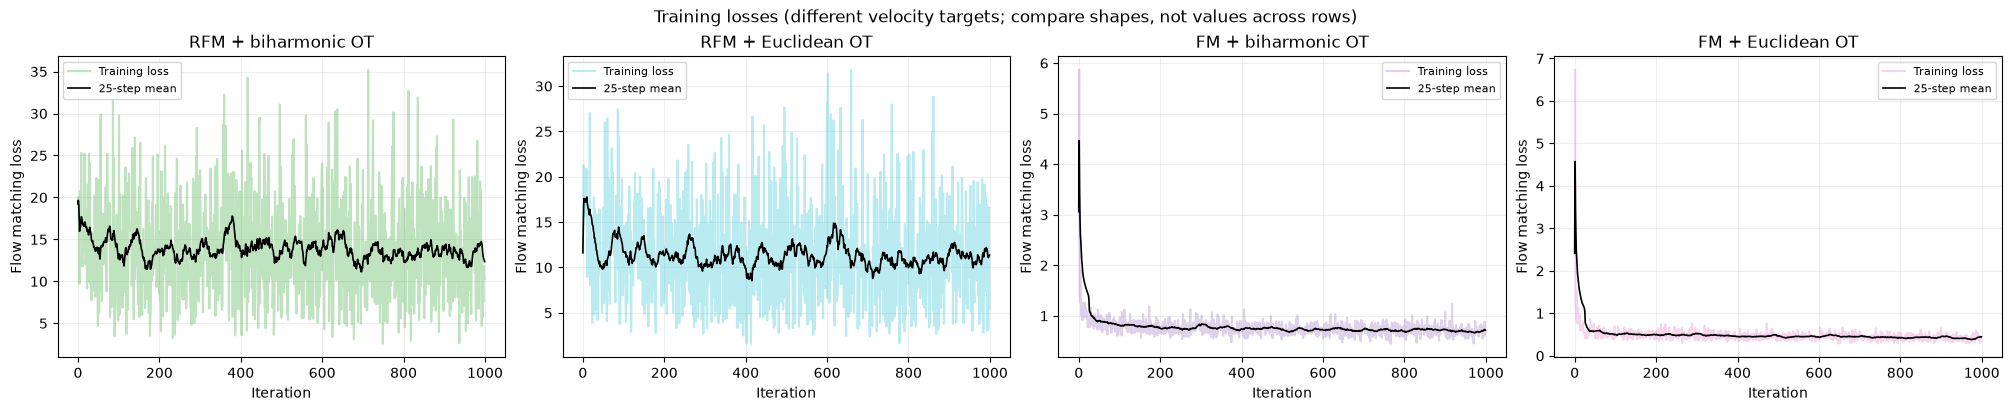

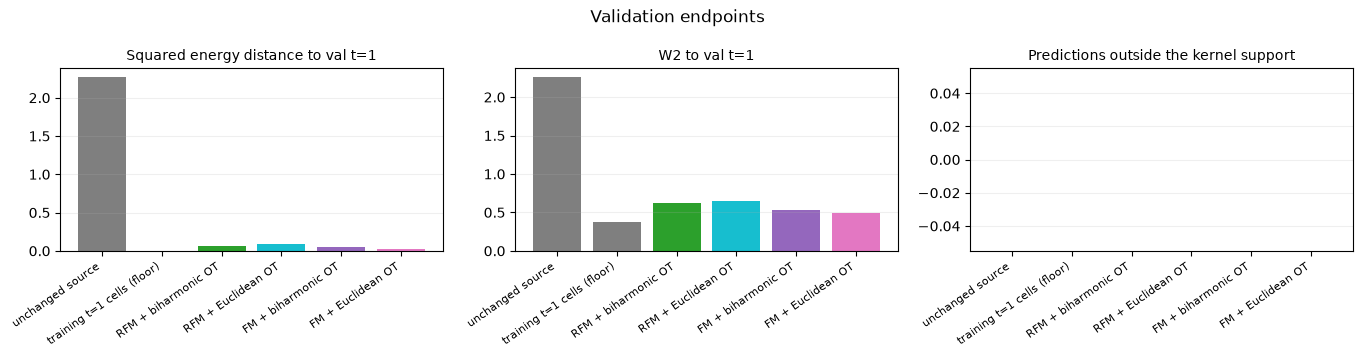

,val t=1,RFM + biharmonic OT,RFM + Euclidean OT,FM + biharmonic OT,FM + Euclidean OT
mean MDK,5.092,4.873,5.182,5.141,5.180
mean RPL12,5.019,5.063,4.793,4.831,4.952
mean VIM,5.658,5.510,5.533,5.669,5.735
sd MDK,0.641,0.681,0.708,0.678,0.634
sd RPL12,0.561,0.287,0.292,0.359,0.464
sd VIM,0.749,0.853,0.823,0.693,0.697


In [17]:
cmp_evaluation, cmp_predicted = {}, {}
for split_name in ("val", "test"):
    cmp_evaluation[split_name], cmp_predicted[split_name] = evaluate_split(cmp_models, split_name)
cmp_endpoint_metrics = pd.concat(cmp_evaluation, names=["split", "cloud"])
display(cmp_endpoint_metrics.round(4))

plotting.plot_loss_panels(
    cmp_losses, cmp_colors, "Training losses (different velocity targets; compare shapes, not values across rows)"
)
cells.plot_metric_bars(cmp_evaluation["val"], [
    ("energy_distance_squared", "Squared energy distance to val t=1"),
    ("wasserstein_2", "W2 to val t=1"),
    ("unsupported_fraction", "Predictions outside the kernel support"),
], cmp_colors, title="Validation endpoints")
display(moment_table({"val t=1": cells_at("val", target_time), **cmp_predicted["val"]}).round(3))

## Intermediate marginals against the observed intermediate days

The data observe the cells at $t=0.25, 0.5, 0.75$ too, which no model is trained on. Here each model pushes the held-out $t=0$ cells of a split through its learned field to those times (with the predictor's Tsit5 settings; the endpoint at $t=1$ is checked against `predict`), and the result is compared with the cells of the same split observed on that day.

This asks more than the models are trained for. Flow matching between two snapshots does not know when the intermediate cells were sampled, so nothing ties model time to experimental time. A model can follow the right states on the wrong clock. The tables therefore also report the **time-matched floor** (training cells of the same day, an independent sample) and the unchanged source, and the plot shows each metric over time.

In [18]:
intermediate_times = np.array([0.0, 0.25, 0.5, 0.75, 1.0], dtype=np.float32)
intermediate_rows, intermediate_states = [], {}
for split_name in ("val", "test"):
    source = cells_at(split_name, source_time)
    for name, model in cmp_models.items():
        intermediate_states[split_name, name] = flows.integrate_learned_paths(model, source, intermediate_times)[0]
    for k, t in enumerate(intermediate_times[1:-1], start=1):
        reference = cells_at(split_name, t)
        clouds = {"unchanged source": source, "training cells of the day (floor)": cells_at("train", t)}
        clouds |= {name: intermediate_states[split_name, name][:, k] for name in cmp_models}
        table = cells.metric_table(clouds, reference, cloud)
        intermediate_rows.append(table.assign(split=split_name, time=float(t)).rename_axis("cloud").reset_index())
intermediate_metrics = pd.concat(intermediate_rows).set_index(["split", "time", "cloud"])
display(intermediate_metrics.loc["val"][["energy_distance_squared", "wasserstein_2", "mean_error_to_target",
                                          "unsupported_fraction", "negative_expression_fraction"]].round(4))

energy_distance_squared  \
time cloud                                                        
0.25 unchanged source                                    0.7225   
     training cells of the day (floor)                   0.0021   
     RFM + biharmonic OT                                 0.7488   
     RFM + Euclidean OT                                  0.7262   
     FM + biharmonic OT                                  0.4010   
     FM + Euclidean OT                                   0.3379   
0.50 unchanged source                                    1.0314   
     training cells of the day (floor)                   0.0061   
     RFM + biharmonic OT                                 0.9555   
     RFM + Euclidean OT                                  0.9097   
     FM + biharmonic OT                                  0.4338   
     FM + Euclidean OT                                   0.3462   
0.75 unchanged source                                    0.9664   
     training cells of the day (floor)                   0.0026   
     RFM + biharmonic OT                                 0.5718   
     RFM + Euclidean OT                                  0.6517   
     FM + biharmonic OT                                  0.2412   
     FM + Euclidean OT                                   0.1844   

                                        wasserstein_2  mean_error_to_target  \
time cloud                                                                    
0.25 unchanged source                          1.2550                1.1677   
     training cells of the day (floor)         0.2695                0.0373   
     RFM + biharmonic OT                       1.1913                1.0869   
     RFM + Euclidean OT                        1.1549                1.0518   
     FM + biharmonic OT                        0.8923                0.7910   
     FM + Euclidean OT                         0.8569                0.7443   
0.50 unchanged source                          1.5685                1.4215   
     training cells of the day (floor)         0.3239                0.0850   
     RFM + biharmonic OT                       1.3537                1.2662   
     RFM + Euclidean OT                        1.2934                1.2115   
     FM + biharmonic OT                        0.9502                0.7859   
     FM + Euclidean OT                         0.8856                0.7245   
0.75 unchanged source                          1.5234                1.3556   
     training cells of the day (floor)         0.3510                0.0296   
     RFM + biharmonic OT                       1.0843                0.9513   
     RFM + Euclidean OT                        1.1225                0.9950   
     FM + biharmonic OT                        0.7439                0.5637   
     FM + Euclidean OT                         0.6780                0.5216   

                                        unsupported_fraction  \
time cloud                                                     
0.25 unchanged source                                    0.0   
     training cells of the day (floor)                   0.0   
     RFM + biharmonic OT                                 0.0   
     RFM + Euclidean OT                                  0.0   
     FM + biharmonic OT                                  0.0   
     FM + Euclidean OT                                   0.0   
0.50 unchanged source                                    0.0   
     training cells of the day (floor)                   0.0   
     RFM + biharmonic OT                                 0.0   
     RFM + Euclidean OT                                  0.0   
     FM + biharmonic OT                                  0.0   
     FM + Euclidean OT                                   0.0   
0.75 unchanged source                                    0.0   
     training cells of the day (floor)                   0.0   
     RFM + biharmonic OT                                 0.0   
     RFM + Euclidean OT       

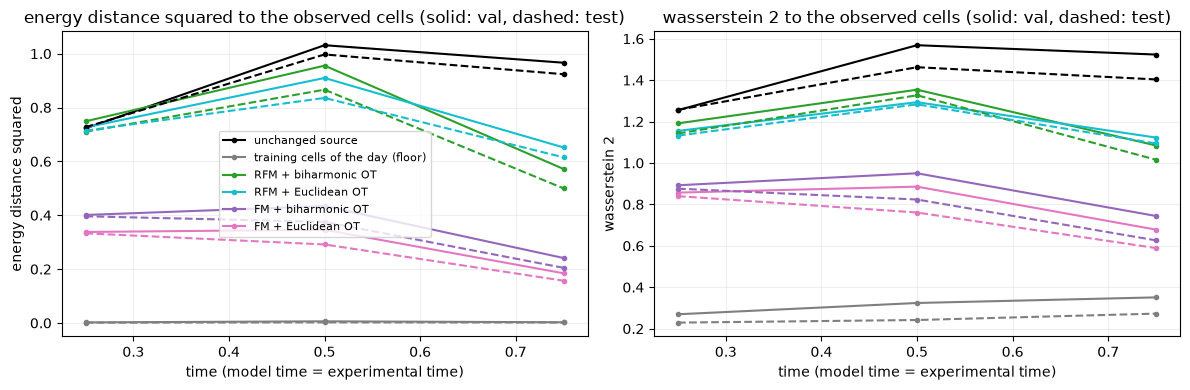

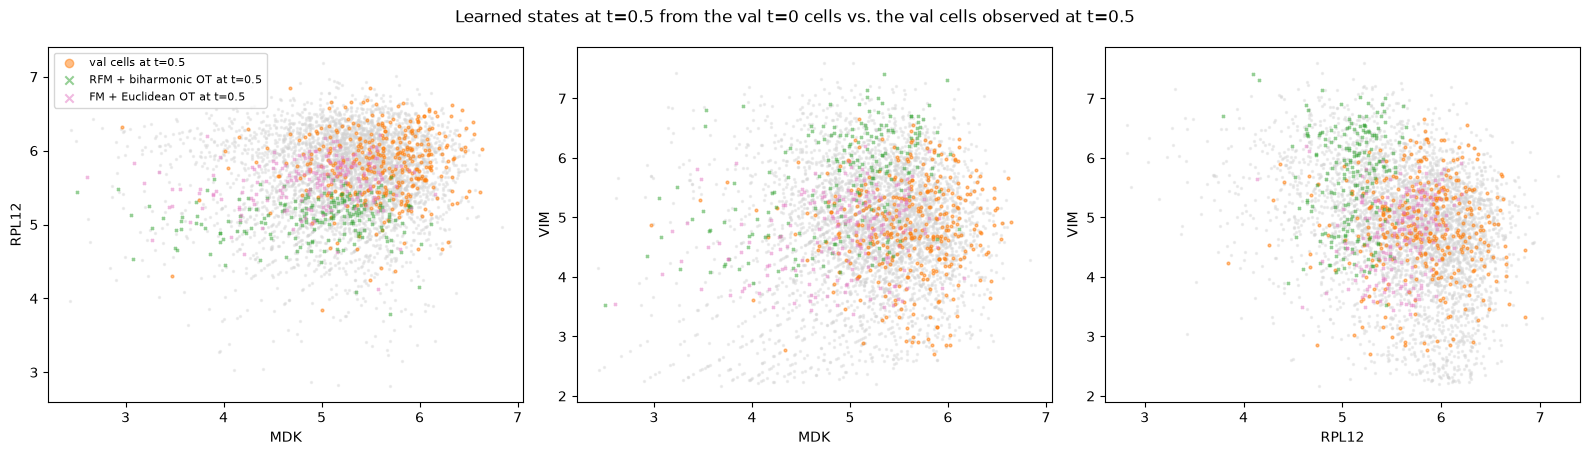

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
line_colors = {"unchanged source": "black", "training cells of the day (floor)": "tab:gray", **cmp_colors}
for ax, metric in zip(axes, ["energy_distance_squared", "wasserstein_2"]):
    for split_name, style in [("val", "-"), ("test", "--")]:
        table = intermediate_metrics.loc[split_name][metric].unstack("cloud")
        for name in line_colors:
            ax.plot(table.index, table[name], style, marker="o", ms=3, color=line_colors[name],
                    label=name if split_name == "val" else None)
    ax.set(xlabel="time (model time = experimental time)", ylabel=metric.replace("_", " "),
           title=f"{metric.replace('_', ' ')} to the observed cells (solid: val, dashed: test)")
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

cells.plot_clouds(construction_points, {
    "val cells at t=0.5": (cells_at("val", 0.5), {"color": "tab:orange"}),
    **{f"{name} at t=0.5": (intermediate_states["val", name][:, 2], {"color": cmp_colors[name], "marker": "x"})
       for name in ["RFM + biharmonic OT", "FM + Euclidean OT"]},
}, genes, "Learned states at t=0.5 from the val t=0 cells vs. the val cells observed at t=0.5")

## Learned trajectories of held-out cells

Finally, the paths themselves. Eight distinct held-out $t=0$ test cells are integrated through each learned field from $t=0$ to $t=1$ (Tsit5, 101 saved times, no clipping). For every model, the table reports, over the saved states:

- `mean_path_length` in log-expression units;
- `paths_leaving_support`: the fraction of paths with at least one saved state outside the kernel support, and `fraction_saved_points_supported`;
- `max_support_ratio`: the largest $\min_j\|x-x_j\|/(\delta\rho_j)$ along the paths (above 1 = outside the support);
- `paths_with_negative_expression`;
- the median distance of the saved states to the nearest graph (training) point.

A straight FM path may cut through regions without training cells; an RFM path is pushed along the graph.

,mean_path_length,paths_leaving_support,fraction_saved_points_supported,max_support_ratio,paths_with_negative_expression,median_distance_to_graph
RFM + biharmonic OT,2.2725,0.0,1.0,0.3180,0.0,0.1110
RFM + Euclidean OT,2.4106,0.0,1.0,0.3328,0.0,0.1363
FM + biharmonic OT,2.5459,0.0,1.0,0.3184,0.0,0.1076
FM + Euclidean OT,2.5042,0.0,1.0,0.3339,0.0,0.1024


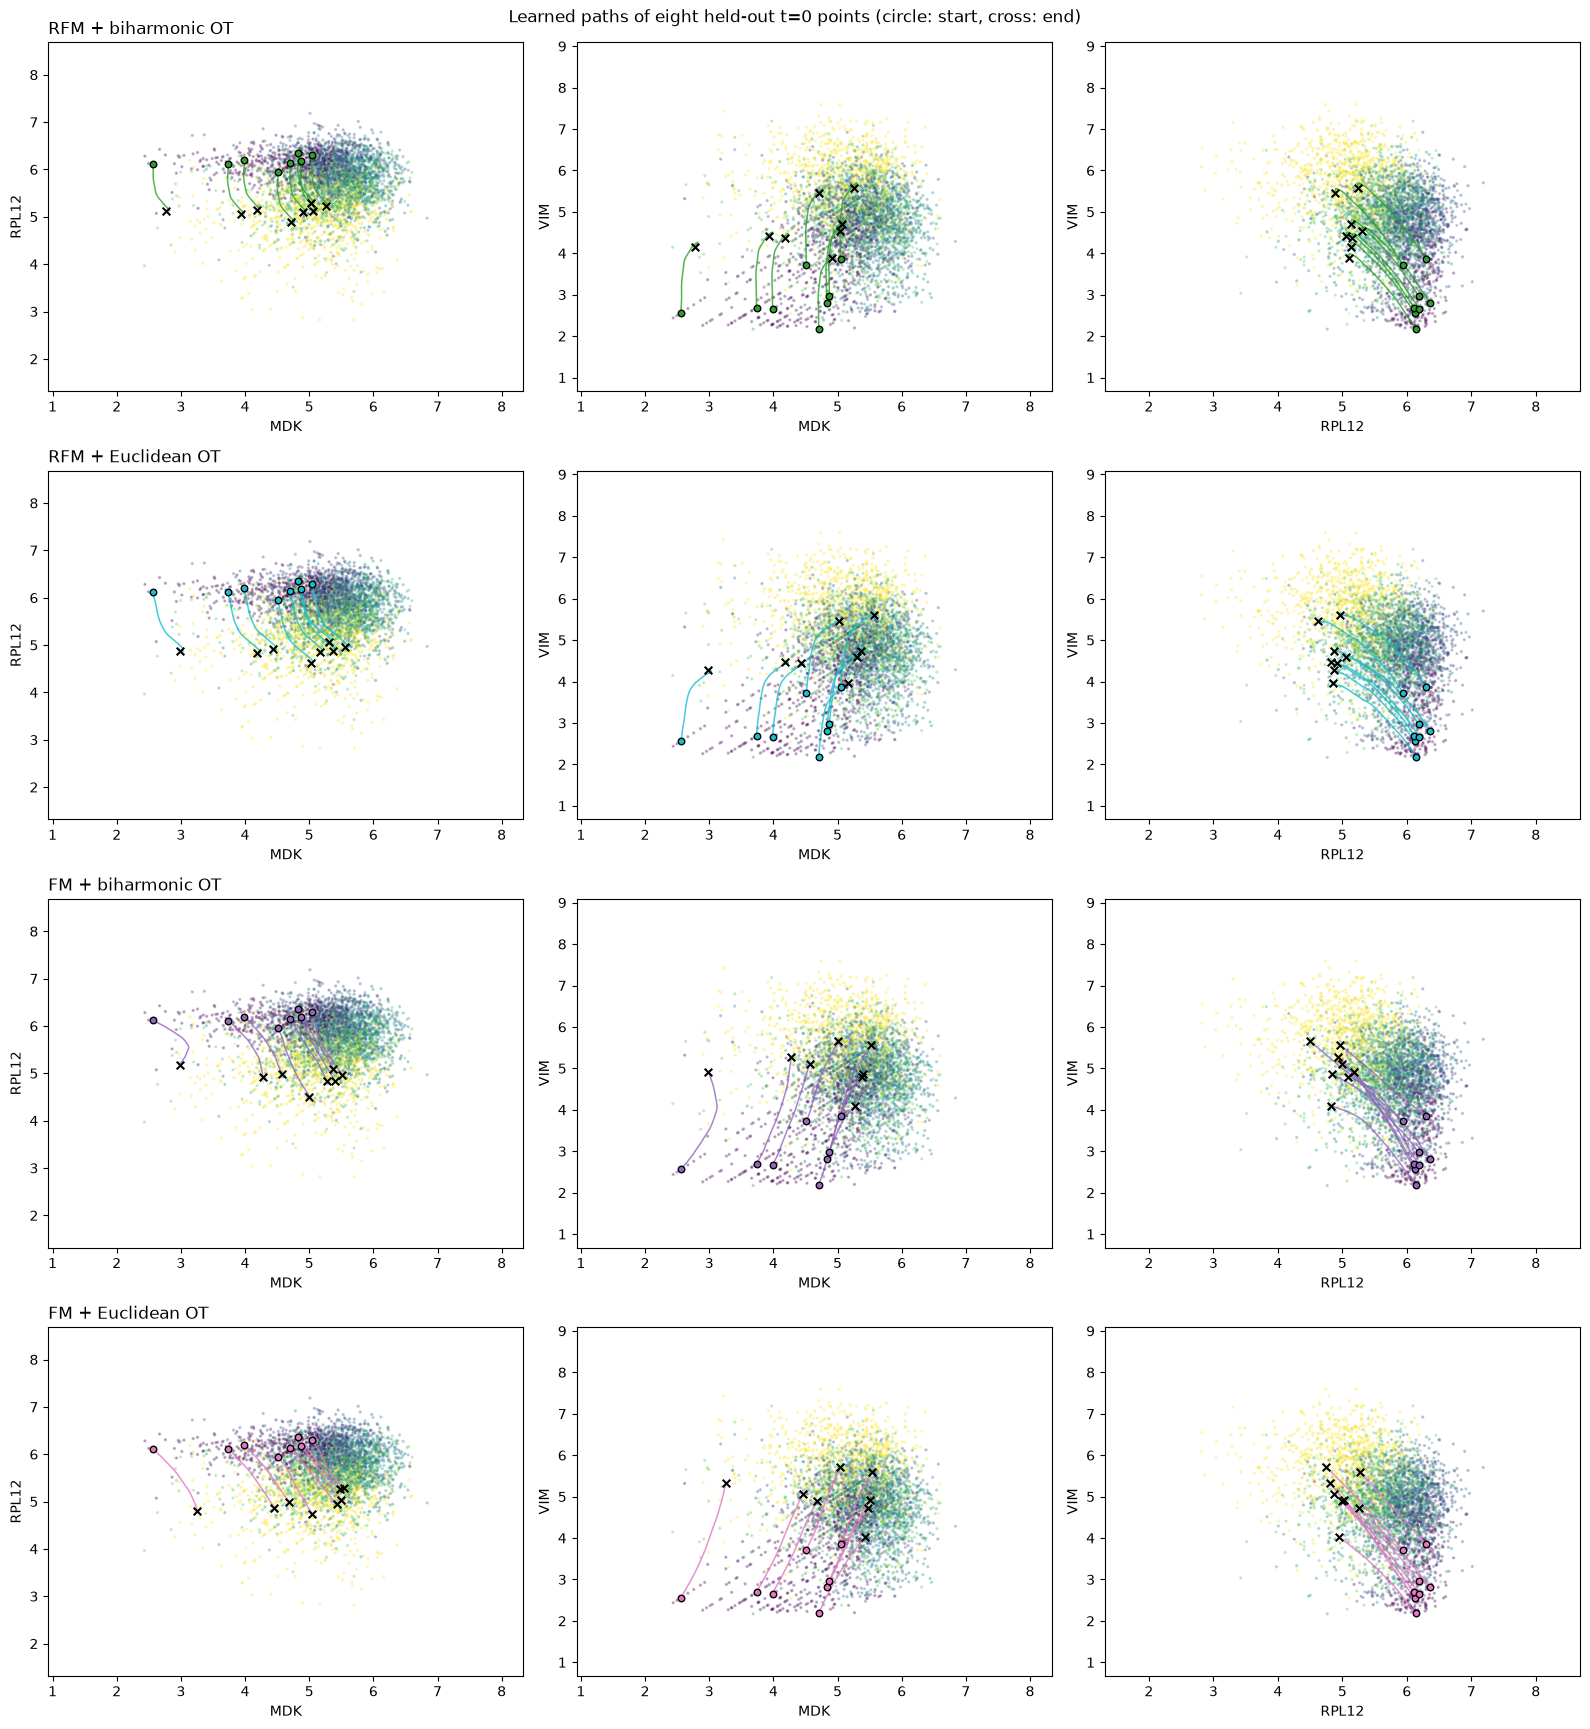

In [20]:
path_candidates = cells.unique_points(cells_at("test", source_time))[0]
path_starts = path_candidates[np.random.default_rng(2027).choice(len(path_candidates), 8, replace=False)]
path_times = np.linspace(0.0, 1.0, 101, dtype=np.float32)
cmp_trajectories = {name: flows.integrate_learned_paths(model, path_starts, path_times)[0] for name, model in cmp_models.items()}
cmp_path_metrics = pd.DataFrame({name: cells.path_metrics(cloud, paths) for name, paths in cmp_trajectories.items()}).T
display(cmp_path_metrics.round(4))
cells.plot_paths(construction_points, construction_time, cmp_trajectories, path_times, genes,
                 "Learned paths of eight held-out t=0 points (circle: start, cross: end)", colors=cmp_colors)

In [21]:
# One table per model: validation endpoints, intermediate fit (mean over t=0.25, 0.5, 0.75 on val),
# path geometry on the shared held-out starts, and training cost.
cmp_summary = pd.concat({
    "val endpoint": cmp_evaluation["val"].loc[list(cmp_models), ["energy_distance_squared", "wasserstein_2", "unsupported_fraction",
                                                                  "negative_expression_fraction", "diverged_fraction"]],
    "val intermediate (mean)": intermediate_metrics.loc["val"][["energy_distance_squared", "wasserstein_2"]]
    .groupby("cloud").mean().loc[list(cmp_models)],
    "paths": cmp_path_metrics[["mean_path_length", "paths_leaving_support", "max_support_ratio"]],
}, axis=1)
cmp_summary[("training", "seconds")] = pd.Series(cmp_training_seconds)
display(cmp_summary.round(4))

val endpoint                \
                    energy_distance_squared wasserstein_2   
RFM + biharmonic OT                  0.0619        0.6249   
RFM + Euclidean OT                   0.0900        0.6544   
FM + biharmonic OT                   0.0476        0.5322   
FM + Euclidean OT                    0.0196        0.4902   

                                                                       \
                    unsupported_fraction negative_expression_fraction   
RFM + biharmonic OT                  0.0                          0.0   
RFM + Euclidean OT                   0.0                          0.0   
FM + biharmonic OT                   0.0                          0.0   
FM + Euclidean OT                    0.0                          0.0   

                                      val intermediate (mean)                \
                    diverged_fraction energy_distance_squared wasserstein_2   
RFM + biharmonic OT               0.0                  0.7587        1.2097   
RFM + Euclidean OT                0.0                  0.7625        1.1903   
FM + biharmonic OT                0.0                  0.3587        0.8621   
FM + Euclidean OT                 0.0                  0.2895        0.8068   

                               paths                                          \
                    mean_path_length paths_leaving_support max_support_ratio   
RFM + biharmonic OT           2.2725                   0.0            0.3180   
RFM + Euclidean OT            2.4106                   0.0            0.3328   
FM + biharmonic OT            2.5459                   0.0            0.3184   
FM + Euclidean OT             2.5042                   0.0            0.3339   

                    training  
                     seconds  
RFM + biharmonic OT  20.7103  
RFM + Euclidean OT   16.9474  
FM + biharmonic OT   10.9899  
FM + Euclidean OT     8.7849

## Reading the results

Numbers below are from the saved run with the `parameters.json` network (seed 2026, 1,000 iterations, one V100 GPU); rerun to check them after changing any setting.

**Data, split and graph.** 16,616 of 18,203 cells (91%) express all three genes: 74% of the $t=0$ cells (VIM is the limiting gene) and 90–97% at later times. The graph uses 4,000 training cells (473 to 916 per time point), all distinct points; no validation or test cell enters it.

**Geometry.** All five profiles give a connected graph with the swiss roll's settings. The leading biharmonic coordinate follows time ($|\rho|=0.54$ for the variable Gaussian). The exact RFM field of every smooth profile reaches its target from all 12 starts: the variable Gaussian to within 0.001 (of 2.18), the compact polynomial and the bump to within 0.02, the fixed Gaussian to within 0.12; binary CkNN does not move. The variable-Gaussian paths are 2.92 long, 34% longer than the straight distance, and stay well inside the kernel support (largest support ratio 0.31).

**Endpoints ($t=1$).**

| | val: squared energy distance | val: $W_2$ | test: squared energy distance | test: $W_2$ |
| --- | --- | --- | --- | --- |
| unchanged source | 2.27 | 2.26 | 2.28 | 2.33 |
| training $t=1$ cells (floor) | 0.004 | 0.38 | 0.002 | 0.31 |
| RFM + biharmonic OT | 0.062 | 0.62 | 0.066 | 0.61 |
| RFM + Euclidean OT | 0.090 | 0.65 | 0.126 | 0.66 |
| FM + biharmonic OT | 0.048 | 0.53 | 0.069 | 0.50 |
| **FM + Euclidean OT** | **0.020** | **0.49** | **0.035** | **0.44** |

- **All four models transport the cells close to the target**, cutting the do-nothing energy distance by a factor of 18 to 116. No prediction leaves the kernel support, is negative or diverges.
- **FM + Euclidean OT is best on both splits, RFM + Euclidean OT worst.** RFM + biharmonic and FM + biharmonic swap places between the splits (0.062 vs. 0.048 on val, 0.066 vs. 0.069 on test).
- **RFM predictions are too narrow in RPL12** (standard deviation 0.29 for both RFM models vs. 0.56 observed on val; FM: 0.36 and 0.46) and too wide in VIM (0.82–0.85 vs. 0.75). RFM + biharmonic also stops short of the target: its mean stays below the observed one in MDK (4.87 vs. 5.09) and VIM (5.51 vs. 5.66), and its mean error is twice that of FM + Euclidean (0.27 vs. 0.13).
- **The couplings are close to independent** (transported biharmonic cost 0.0096 and 0.0098, independent 0.0101), as on the swiss roll. The two RFM rows still differ (0.062 vs. 0.090 on val, 0.066 vs. 0.126 on test); with couplings this similar, one seed cannot separate a coupling effect from training noise.

**Intermediate days.** Both FM models stay 2.5 to 3 times closer to the observed cells than doing nothing (mean squared energy distance over $t=0.25, 0.5, 0.75$ on val: 0.29–0.36, against 0.91). The RFM models reach 0.76: no better than the unchanged source at $t=0.25$ (0.73–0.75 vs. 0.72), slightly better at $t=0.5$ (0.91–0.96 vs. 1.03), and clearly better only at $t=0.75$ (0.57–0.65 vs. 0.97). The test split shows the same pattern.

**Paths.** All learned paths stay inside the kernel support. RFM paths are shorter than FM paths (2.27 and 2.41 vs. 2.50–2.55). For RFM + biharmonic this mostly reflects that it moves the cells less far (see the endpoint means above), not a shorter route to the same place.

**Against the compact toy network** (`flows.DEFAULT_ARCHITECTURE`, previous run on a CPU). The `parameters.json` network, with 4.3 million parameters, does not change the ranking. Endpoint distances move by about as much as they differ between val and test (FM + Euclidean: 0.015 → 0.020 on val, 0.025 → 0.035 on test; RFM + biharmonic: 0.088 → 0.062 on val, 0.050 → 0.066 on test). The RFM fit of the intermediate days improves (mean 0.85–1.02 → 0.76) but stays far behind FM (0.31–0.34 → 0.29–0.36).

**Reading.** In MDK, RPL12 and VIM the cells form one compact, connected cloud, and straight lines between source and target cells stay inside it. The biharmonic geometry therefore offers no detour worth taking: RFM does not beat FM + Euclidean OT at the endpoint and fits the intermediate days much worse, at 1.5 to 2.4 times the training cost on the GPU (17–21 s vs. 9–11 s). A geometry-aware path should matter more in gene views where the data has a curved or branched shape that straight lines leave.